# Data split notes
- Use the 500 official test pairs as test set
- Select the trainval sets of group44000, group50600, group77000 as validation set
- Use the rest as training set

# Intersection over union (IoU) notes
Use 0.5 as IoU threshold

# Import libraries

In [1]:
import shutil
import os
from pathlib import Path

import pandas as pd
from ultralytics import YOLO
import numpy as np
from ultralytics.data.utils import visualize_image_annotations

# Convert DeepPCB dataset to YOLO format
You need to download the dataset yourself

In [2]:
# DeepPCB image dimensions
img_size = 640

### Create `PCBData_yolo` directories if not already existing

In [3]:
for folder in ["images", "labels"]:
    for set in ["train", "val", "test"]:
        Path(f"PCBData_yolo/{folder}/{set}").mkdir(parents=True, exist_ok=True)

### Function to convert annotations to YOLO format

In [4]:
def convert_annotations_to_yolo(annotations: pd.DataFrame):
    x_center = ((annotations['x1'] + annotations['x2']) / 2 / img_size).rename("x_center")
    y_center = ((annotations['y1'] + annotations['y2']) / 2 / img_size).rename("y_center")
    width = ((annotations['x2'] - annotations['x1']) / img_size).rename("width")
    height = ((annotations['y2'] - annotations['y1']) / img_size).rename("height")

    return pd.concat([annotations['type'], x_center, y_center, width, height], axis=1)

### Convert the dataset

Test set

In [5]:
test_set_paths = pd.read_csv("PCBData/test.txt", sep=" ", header=None, names=["image", "label"])

for image_path in test_set_paths['image']:
    # Get path of test image to copy
    test_image_filename = f"{image_path.split(".")[0]}_test"  # Filename without extension
    test_image_path = ".".join([test_image_filename, image_path.split(".")[1]])

    copied_filename = os.path.split(image_path)[-1]  # New name of the copied image file
    shutil.copy2(os.path.join("PCBData", test_image_path), os.path.join("PCBData_yolo/images/test", copied_filename))

for label_path in test_set_paths['label']:
    # Convert labels to YOLO format
    annotations = pd.read_csv(
        os.path.join("PCBData", label_path), 
        sep=" ", 
        header=None, 
        names=["x1", "y1", "x2", "y2", "type"]
    )

    # Export the converted labels file
    label_filename = os.path.split(label_path)[-1]
    annotations_yolo = convert_annotations_to_yolo(annotations)
    annotations_yolo.to_csv(
        os.path.join("PCBData_yolo/labels/test/", label_filename), 
        sep=" ", 
        header=False,
        index=False
    )

Training and validation sets

In [6]:
trainval_set_paths = pd.read_csv("PCBData/trainval.txt", sep=" ", header=None, names=["image", "label"])
val_set_groups = ["group44000", "group50600", "group77000"]

for image_path in trainval_set_paths['image']:
    # Get path of tested image to copy
    tested_image_filename = f"{image_path.split(".")[0]}_test"  # Filename without extension
    tested_image_path = ".".join([tested_image_filename, image_path.split(".")[1]])

    copied_filename = os.path.split(image_path)[-1]  # New name of the copied image file

    # Split between training and validation sets
    set = "val" if any(val_set_group in image_path for val_set_group in val_set_groups) else "train"
    shutil.copy2(
        os.path.join("PCBData", tested_image_path),
        os.path.join(f"PCBData_yolo/images/{set}/", copied_filename)
    )

for label_path in trainval_set_paths['label']:
    # Convert labels to YOLO format
    annotations = pd.read_csv(
        os.path.join("PCBData", label_path),
        sep=" ",
        header=None,
        names=["x1", "y1", "x2", "y2", "type"]
    )

    # Split between training and validation sets
    set = "val" if any(val_set_group in label_path for val_set_group in val_set_groups) else "train"

    # Export the converted labels file
    label_filename = os.path.split(label_path)[-1]
    annotations_yolo = convert_annotations_to_yolo(annotations)
    annotations_yolo.to_csv(
        os.path.join(f"PCBData_yolo/labels/{set}/", label_filename),
        sep=" ",
        header=False,
        index=False
    )

# Train YOLOv8n model

Perform hyperparameter tuning
- Batch size: 16, 32, 64
- Learning rate: ~~1e-5, 1e-4, 1e-3, 1e-2~~ 0.01
- Number of epochs: 100, 150, 200

In [3]:
batch_sizes = [64, 32, 16]
# learning_rates = [1e-5, 1e-4, 1e-3, 1e-2]
num_epochs = [100, 150, 200]
dataset_file = "deeppcb.yaml"

In [ ]:
# Store results of each hyperparameter combination
tuning_metrics = pd.DataFrame(columns=['batch_size', 'num_epoch', 'f1_score', 'precision', 'recall', 'map50', 'map50-95'])

for batch_size in batch_sizes:
    for num_epoch in num_epochs:
        # Load the model
        yolov8n = YOLO("yolov8n.pt")

        training_results = yolov8n.train(
            data=dataset_file,
            epochs=num_epoch,
            batch=batch_size,
            imgsz=img_size,
            seed=67,
            val=True,
            name=f"train_batch_{batch_size}_epoch_{num_epoch}"
        )

        test_results = yolov8n.val(
            data=dataset_file,
            imgsz=img_size,
            iou=0.5,
            split="val",  # Validate hyperparameter combination on validation set!
            name=f"val_batch_{batch_size}_epoch_{num_epoch}"
        )

        precision = np.mean(test_results.box.p)
        recall = np.mean(test_results.box.r)
        f1_score = (2 * precision * recall) / (precision + recall)
        map50 = np.mean(test_results.box.map50)
        map5095 = np.mean(test_results.box.map)

        # Store the hyperparameter combination's results
        tuning_metrics.loc[len(tuning_metrics)] = [batch_size, num_epoch, f1_score, precision, recall, map50, map5095]

Ultralytics 8.4.216  Python-3.12.6 torch-2.15.0+cu134 CUDA:0 (NVIDIA GeForce RTX 3070, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=deeppcb.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_batch_64_epoch_100, nbs=64, nms=None, opset=None, optimiz

Print the hyperparameter combination with the highest F1 score

In [8]:
best_settings = tuning_metrics.loc[tuning_metrics['f1_score'].idxmax()]
best_settings

batch_size     32.000000
num_epoch     150.000000
f1_score        0.896853
precision       0.911959
recall          0.882238
map50           0.925551
map50-95        0.700939
Name: 4, dtype: float64

In [9]:
tuning_metrics

,batch_size,num_epoch,f1_score,precision,recall,map50,map50-95
0,64.0,100.0,0.883289,0.908911,0.859072,0.913647,0.693334
1,64.0,150.0,0.879062,0.884719,0.873478,0.912486,0.687013
2,64.0,200.0,0.894429,0.907222,0.881991,0.918476,0.700492
3,32.0,100.0,0.888662,0.905463,0.872474,0.925764,0.702042
4,32.0,150.0,0.896853,0.911959,0.882238,0.925551,0.700939
5,32.0,200.0,0.885591,0.916480,0.856717,0.926535,0.708848
6,16.0,100.0,0.880767,0.880913,0.880622,0.920492,0.695049
7,16.0,150.0,0.890971,0.898357,0.883705,0.927772,0.707450
8,16.0,200.0,0.885510,0.900571,0.870944,0.924151,0.701379


# Test hyperparameter tuned model
Best hyperparameter combination
- batch size: 32
- no. of epochs: 150
- F1 score: 0.896853

In [4]:
best_batch_size = 32
best_num_epochs = 150

# Load the pre-trained model
best_model = YOLO(f"runs/detect/train_batch_{best_batch_size}_epoch_{best_num_epochs}/weights/best.pt")

testing_results = best_model.val(
    data=dataset_file,
    imgsz=img_size,
    iou=0.5,
    split="test",
    name=f"test_batch_{best_batch_size}_epoch_{best_num_epochs}"
)

testing_precision = np.mean(testing_results.box.p)
testing_recall = np.mean(testing_results.box.r)
testing_f1_score = (2 * testing_precision * testing_recall) / (testing_precision + testing_recall)
testing_map50 = np.mean(testing_results.box.map50)
testing_map5095 = np.mean(testing_results.box.map)

print("Precision:", testing_precision)
print("Recall:", testing_recall)
print("F1 score:", testing_f1_score)
print("MAP50:", testing_map50)
print("MAP50-95:", testing_map5095)

print("per-class F1 score:", (2 * testing_results.box.p * testing_results.box.r) / (testing_results.box.p + testing_results.box.r))

Ultralytics 8.4.216  Python-3.12.6 torch-2.15.0+cu134 CUDA:0 (NVIDIA GeForce RTX 3070, 8192MiB)
Model summary (fused): 73 layers, 3,134,165 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 259.9±90.8 MB/s, size: 39.5 KB)
val: Scanning C:\Users\charl\csit5410-project\PCBData_yolo\labels\test.cache... 500 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 500/500  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 1.5it/s 21.4s0.1s
                   all        500       3140       0.94      0.927      0.958      0.743
                  open        482        659       0.93      0.932      0.957      0.654
                 short        368        478      0.953      0.811      0.903      0.608
             mousebite        413        586      0.969      0.951      0.966      0.728
                  spur        373        483      0.989      0.911      0.974      0.731
                

# Present example predictions

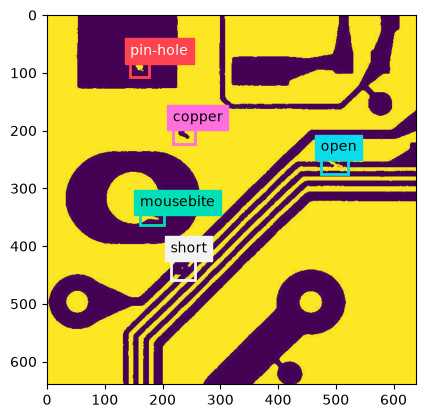


0: 640x640 1 open, 1 short, 1 mousebite, 1 copper, 1 pin-hole, 9.6ms
Speed: 1.8ms preprocess, 9.6ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)


In [16]:
test_set_dir = 'PCBData_yolo/images/test/'
test_set_annotation_dir = 'PCBData_yolo/labels/test/'
example_filenames = ['12300231.jpg']
example_annotation_filenames = ['12300231.txt']
example_paths = [os.path.join(test_set_dir, example_filename) for example_filename in example_filenames]
example_annotation_paths = [os.path.join(test_set_annotation_dir, example_annotation_filename) for example_annotation_filename in example_annotation_filenames]

label_map = {
    0: "background",
    1: "open",
    2: "short",
    3: "mousebite",
    4: "spur",
    5: "copper",
    6: "pin-hole"
}

for idx, example_annotation_path in enumerate(example_annotation_paths):
    visualize_image_annotations(
        example_paths[idx],
        example_annotation_path,
        label_map
    )

example_results = best_model(example_paths, iou=0.5)

for idx, example_result in enumerate(example_results):
    example_result.save(filename=f"pred_example{idx}.jpg")